# **Memoria de la Práctica 2 de Inteligencia Artificial**
## _Autores: Martín Darío Marmolejo Díaz y Ana Olsson Rodríguez, Grupo 09_

---

### 1. Importa las librerías adecuadas: numpy, pandas, matplotlib, seaborn.

In [242]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---

### 2. Carga los datos con la función read_csv de pandas y visualiza las primeras filas. Después, muestra los tipos de las columnas.

In [243]:
df = pd.read_csv('./data.csv')  # Carga los datos
df.head()  # Visualiza las primeras filas

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [244]:
df.dtypes  # Muestra los tipos de las columnas

Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 81, dtype: object

---

### 3. ¿Cuántas viviendas hay en el conjunto de datos? Muestra las variables, si las hay, que tienen valores nulos e indica cuántos nulos tiene cada una de ellas.

In [245]:
print(df.info()) # Información general del DataFrame, donde podemos observar que hay 1460 filas (1460 viviendas)

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [246]:
df_na = df.isnull().sum() # Cuenta el número de filas con algún valor Null
print(df_na[df_na>0]) # Mostramos las variables que tengan algún valor Null

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


---

### 4. Realiza un estudio individual de las siguientes variables del conjunto de datos
En cada caso:
1. Identifica valores únicos de la columna
2. El tipo (categórica sin orden, categórica con orden, discreto o continuo).
3. Si hay valores nulos o no (puedes utilizar la salida de la pregunta 3 o buscar
específicamente en la columna a tratar).
4. En caso de que la columna tenga valores nulos, el tratamiento que se te
ocurre para trabajar con ellos.
5. Si la columna es numérica obtén valores mínimo y máximo; estudia si hay
outliers.
6. Especifica si decides o no eliminar la columna, porque su aportación puede
ser irrelevante en procesos de modelado posteriores.
7. Si es necesaria una recodificación de la columna, por ser categórica u otra
razón, explica por qué se hace esta conversión y qué método empleas para
llevarla a cabo.
> _Sugerencia: comprueba si los valores de las columnas descritos en el fichero data-description.txt coinciden con los que observamos experimentalmente al ir tratando dichas columnas._

---

##### - Id

In [247]:
column = df["Id"]
# 1. Valores únicos
print(column.unique())

[   1    2    3 ... 1458 1459 1460]


In [248]:
# 2. Tipos de Valores
print(column)

0          1
1          2
2          3
3          4
4          5
        ... 
1455    1456
1456    1457
1457    1458
1458    1459
1459    1460
Name: Id, Length: 1460, dtype: int64


Se trata de una variable discreta.
Los valores son discretos, dado que estos corresponden a los números naturales, ergo, hay una distancia necesaria de una unidad entre cada valor consecutivo, que sería incongruente con ser una variable continua.

In [249]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


In [250]:
# 5. Si la columna es numérica obtén valores mínimo y máximo; estudia si hay outliers
print("Máximo:")
print(column.max())
print("\nMínimo:")
print(column.min())

Q1 = column.quantile(0.25)
Q3 = column.quantile(0.75)
RIC = Q3 - Q1

print("\nOutliers:")
print(column[(column < (Q1 - 1.5 * RIC)) | (column > (Q3 + 1.5 * RIC))])

Máximo:
1460

Mínimo:
1

Outliers:
Series([], Name: Id, dtype: int64)


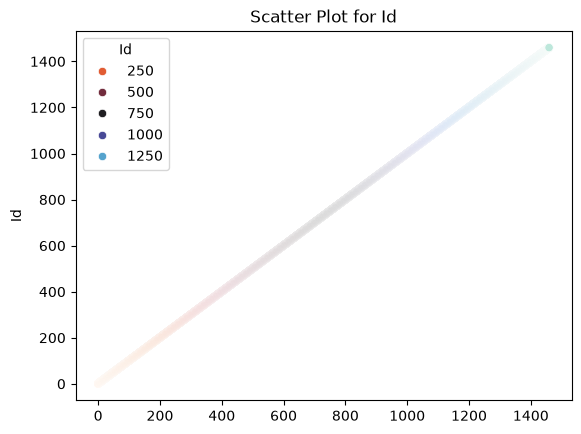

In [251]:
# Scatter plot
sns.scatterplot(x=range(len(column)), y=column, hue=column, palette='icefire_r')
plt.title("Scatter Plot for Id")
plt.show()

7. Recodificación

No es necesaria una recodificación de la columna porque no es razonable partirla en intervalos ni utilizar la transformada logaritmo (al no poseer una distribución de cola pesada)

---

##### - MSSubCLass

In [252]:
column = df["MSSubClass"]
# 1. Valores únicos
print(column.unique())

[ 60  20  70  50 190  45  90 120  30  85  80 160  75 180  40]


In [253]:
# 2. Tipos de Valores
print(column)

0       60
1       20
2       60
3       70
4       60
        ..
1455    60
1456    20
1457    70
1458    20
1459    20
Name: MSSubClass, Length: 1460, dtype: int64


Se trata de una variable categórica ordenable. Según data-description.txt, hay 16 valores posibles, para los cuales se asigna un valor: 20 -> 1-STORY 1946 & NEWER ALL STYLES, 30-> 1-STORY 1945 & OLDER, 40-> 1-STORY W/FINISHED ATTIC ALL AGES, etc. De esta manera es con orden ya que estas categorías son representadas con valores numericos (que son ordenables).

In [254]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


7. Recodificación

Se trata de una categórica ordenable a la que ya se le han sido asignado valores numéricos para sus categorías por lo que no es necesaria una recodificación.

---

##### - MSZoning

In [255]:
column = df["MSZoning"]
# 1. Valores únicos
print(column.unique())

<StringArray>
['RL', 'RM', 'C (all)', 'FV', 'RH']
Length: 5, dtype: str


In [256]:
# 2. Tipos de Valores
print(column)

0       RL
1       RL
2       RL
3       RL
4       RL
        ..
1455    RL
1456    RL
1457    RL
1458    RL
1459    RL
Name: MSZoning, Length: 1460, dtype: str


Se trata de una variable categórica sin orden. Según data-description.txt hay 8 valores posibles para esta, pero no vienen asociados a estos ningún valor númerico o jerarquía entre sí para que les corresponda un orden.

In [257]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


7. Recodificación

Al tratarse de una categórica sin orden, podríamos realizar una codificación one hot que trata de crear tantas variables binarias como categorías, en este caso se necesitaría una codificación de 3 bits.

---

##### - LotFrontage

In [258]:
column = df["LotFrontage"]
# 1. Valores únicos
print(column.unique())

[ 65.  80.  68.  60.  84.  85.  75.  nan  51.  50.  70.  91.  72.  66.
 101.  57.  44. 110.  98.  47. 108. 112.  74. 115.  61.  48.  33.  52.
 100.  24.  89.  63.  76.  81.  95.  69.  21.  32.  78. 121. 122.  40.
 105.  73.  77.  64.  94.  34.  90.  55.  88.  82.  71. 120. 107.  92.
 134.  62.  86. 141.  97.  54.  41.  79. 174.  99.  67.  83.  43. 103.
  93.  30. 129. 140.  35.  37. 118.  87. 116. 150. 111.  49.  96.  59.
  36.  56. 102.  58.  38. 109. 130.  53. 137.  45. 106. 104.  42.  39.
 144. 114. 128. 149. 313. 168. 182. 138. 160. 152. 124. 153.  46.]


In [259]:
# 2. Tipos de Valores
print(column)

0       65.0
1       80.0
2       68.0
3       60.0
4       84.0
        ... 
1455    62.0
1456    85.0
1457    66.0
1458    68.0
1459    75.0
Name: LotFrontage, Length: 1460, dtype: float64


Se trata de una variable continua, ya que según data-description.txt corresponde a una medida espacial en pies de las calles conectadas a la propiedad. De esta manera, siendo una medida espacial y siendo válidos los decimales, es válido cualquier valor entre dos dados, 62.643 y 62.644 por ejemplo, ya que representa una distancia real.

In [260]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[259]


In [261]:
# 4. Lidiar con valores nulos
mean = df["LotFrontage"].mean()
df["LotFrontage"] = df["LotFrontage"].fillna(mean)

LotFrontage cuenta con 259 valores NA, de esta manera, se encuentra por encima del 10% y por debajo del 50% de valores NA en comparación a valores totales, y por esto se elige el metodo de imputación de valores usando "fillna". Así, reemplazamos los valores NA por la media de la columna y hacemos uso del parámetro inplace para que esta sustitución se realice sobre el objeto original.

In [262]:
# 5. Si la columna es numérica obtén valores mínimo y máximo; estudia si hay outliers
print("Máximo:")
print(column.max())
print("\nMínimo:")
print(column.min())

Q1 = column.quantile(0.25)
Q3 = column.quantile(0.75)
RIC = Q3 - Q1

print("\nOutliers:")
print(column[(column < (Q1 - 1.5 * RIC)) | (column > (Q3 + 1.5 * RIC))])

Máximo:
313.0

Mínimo:
21.0

Outliers:
36      112.0
41      115.0
56       24.0
75       21.0
85      121.0
        ...  
1339    120.0
1359    129.0
1361    124.0
1378     21.0
1449     21.0
Name: LotFrontage, Length: 88, dtype: float64


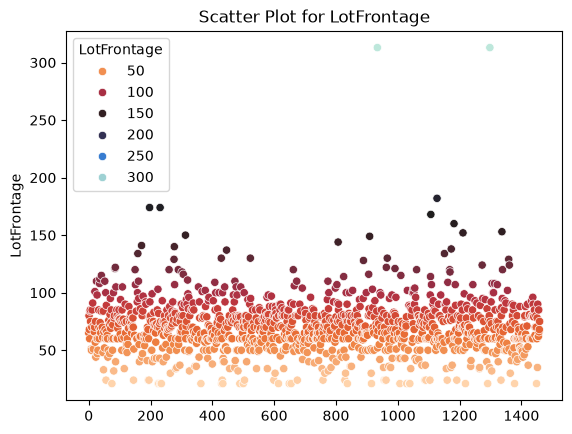

In [263]:
# Scatter plot
sns.scatterplot(x=range(len(column)), y=column, hue=column, palette='icefire_r')
plt.title("Scatter Plot for LotFrontage")
plt.show()

7. Recodificación

Al tratarse de una variable numérica, nos podría interesar partirla en intervalos, para ello vamos a ver la variable sin outliers.

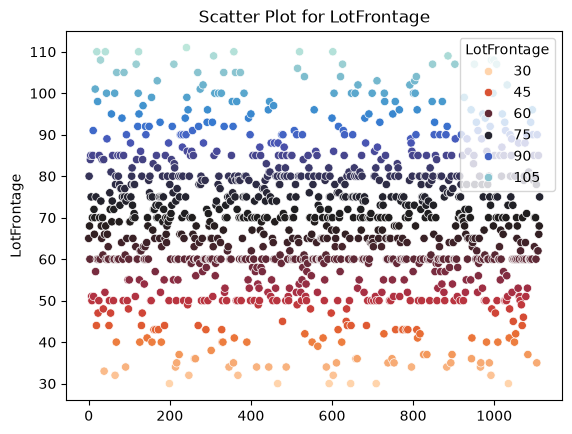

In [264]:
# Scatter plot
column2 = column[(column > (Q1 - 1.5 * RIC))]
column2 = column2[(column2 < (Q3 + 1.5 * RIC))]

sns.scatterplot(x=range(len(column2)), y=column2, hue=column2, palette='icefire_r')
plt.title("Scatter Plot for LotFrontage")
plt.show()

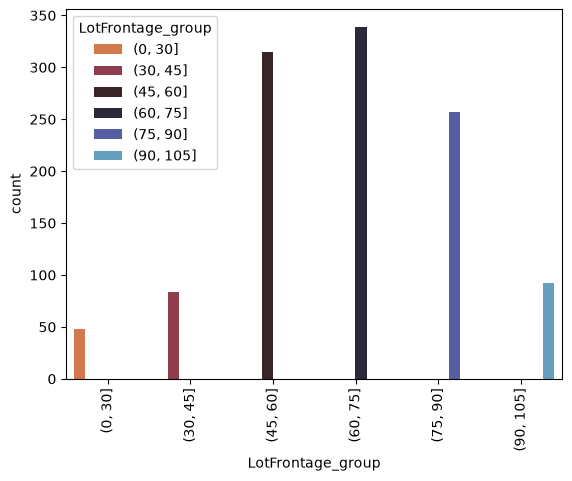

In [265]:
# Escogemos los rangos sugeridos por el hue
bins = [0, 30, 45, 60, 75, 90, 105]
df_test = pd.DataFrame({column.name: column, column.name+'_group': pd.cut(column, bins=bins, right=True)})

ax = sns.countplot(data=df_test, x=column.name+'_group', hue=column.name+'_group', palette='icefire_r')
ax.tick_params(axis='x', labelrotation=90)

---

##### - LotArea

In [266]:
column = df["LotArea"]
# 1. Valores únicos
print(column.unique())

[ 8450  9600 11250 ... 17217 13175  9717]


In [267]:
# 2. Tipos de Valores
print(column)

0        8450
1        9600
2       11250
3        9550
4       14260
        ...  
1455     7917
1456    13175
1457     9042
1458     9717
1459     9937
Name: LotArea, Length: 1460, dtype: int64


Se trata de una variable continua, ya que según data-description.txt corresponde a una medida espacial en pies cuadrados del tamaño de la propiedad. De esta manera, siendo una medida espacial, es válido cualquier valor entre dos dados, 500.643 y 500.644 por ejemplo, ya que representa un área real.

In [268]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


In [269]:
# 5. Si la columna es numérica obtén valores mínimo y máximo; estudia si hay outliers
print("Máximo:")
print(column.max())
print("\nMínimo:")
print(column.min())

Q1 = column.quantile(0.25)
Q3 = column.quantile(0.75)
RIC = Q3 - Q1

print("\nOutliers:")
print(column[(column < (Q1 - 1.5 * RIC)) | (column > (Q3 + 1.5 * RIC))])

Máximo:
215245

Mínimo:
1300

Outliers:
53      50271
66      19900
113     21000
120     21453
159     19378
        ...  
1396    57200
1409    20544
1423    19690
1430    21930
1446    26142
Name: LotArea, Length: 69, dtype: int64


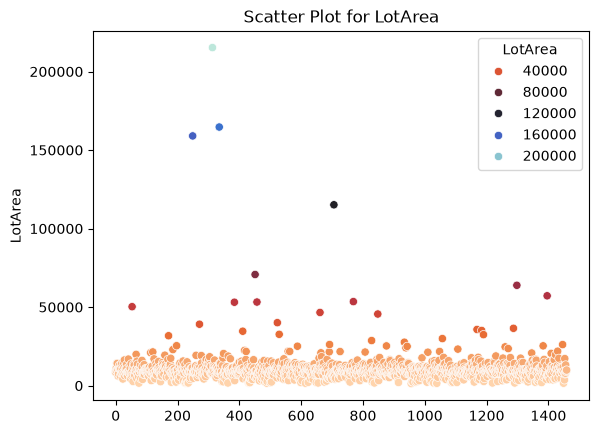

In [270]:
# Scatter plot
sns.scatterplot(x=range(len(column)), y=column, hue=column, palette='icefire_r')
plt.title("Scatter Plot for LotArea")
plt.show()

7. Recodificación

Al tratarse de una variable numérica, nos podría interesar partirla en intervalos, para ello vamos a ver la variable sin outliers.

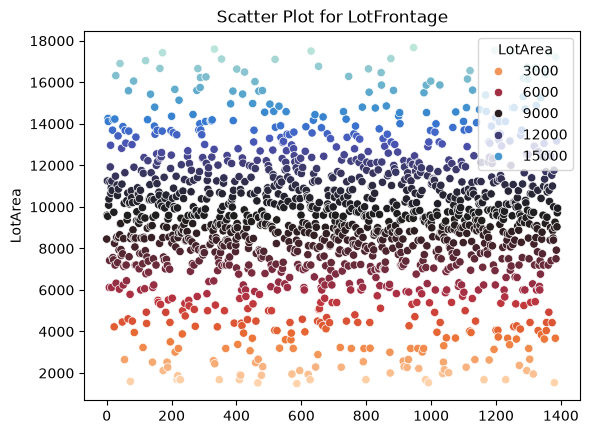

In [271]:
# Scatter plot
column2 = column[(column > (Q1 - 1.5 * RIC))]
column2 = column2[(column2 < (Q3 + 1.5 * RIC))]

sns.scatterplot(x=range(len(column2)), y=column2, hue=column2, palette='icefire_r')
plt.title("Scatter Plot for LotFrontage")
plt.show()

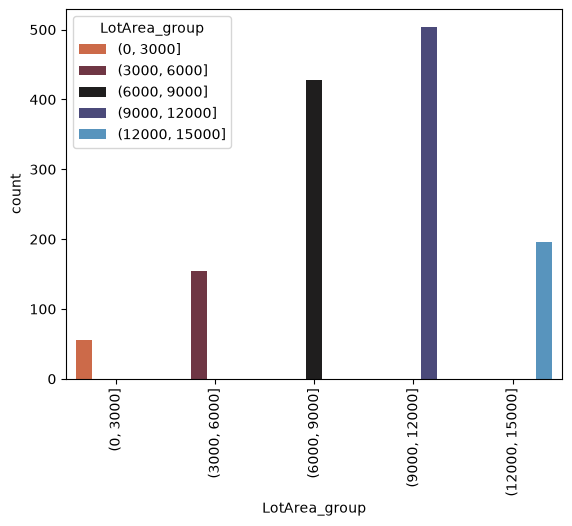

In [272]:
# Escogemos los rangos sugeridos por el hue
bins = [0, 3000, 6000, 9000, 12000, 15000]
df_test = pd.DataFrame({column.name: column, column.name+'_group': pd.cut(column, bins=bins, right=True)})

ax = sns.countplot(data=df_test, x=column.name+'_group', hue=column.name+'_group', palette='icefire_r')
ax.tick_params(axis='x', labelrotation=90)

---

##### - Street

In [273]:
column = df["Street"]
# 1. Valores únicos
print(column.unique())

<StringArray>
['Pave', 'Grvl']
Length: 2, dtype: str


In [274]:
# 2. Tipos de Valores
print(column)

0       Pave
1       Pave
2       Pave
3       Pave
4       Pave
        ... 
1455    Pave
1456    Pave
1457    Pave
1458    Pave
1459    Pave
Name: Street, Length: 1460, dtype: str


Se trata de una variable categórica sin orden con dos valores posibles según data-description.txt: Grvl y Pave. Dado que no
tiene ningun orden asociado a estos valores, es sin orden.

In [275]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


---

##### - Alley

In [276]:
column = df["Alley"]
# 1. Valores únicos
print(column.unique())

<StringArray>
[nan, 'Grvl', 'Pave']
Length: 3, dtype: str


In [277]:
# 2. Tipos de Valores
print(column)

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
1455    NaN
1456    NaN
1457    NaN
1458    NaN
1459    NaN
Name: Alley, Length: 1460, dtype: str


Se trata de una variable categórica sin orden, con dos valores posibles según data-description.txt, paved y gravel. No tienen ninguna jerarquía asociada ni escala inferible, con lo que confirmamos que no es una categórica con orden.

In [278]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[1369]


In [279]:
# 4. Lidiar con valores nulos
df = df.dropna(axis=1, thresh= len(df)//2 + 1)

Se hace uso de dropna para deshacerse de la columna en su totalidad, ya que sus valores son en su mayoría NAs (>50%). Se usa axis=1 para que sea la columna lo que es eliminado y no la fila, y se usa thresh igual a la mitad de la longitud del DataFrame, condición que eliminaría además cualquier otra columna con mas de 50% de valores NA, pero que solo cumple Alley. Por último se usa inplace para modificar el objeto en sí y no devolver meramente un Dataframe equivalente sin esa columna.

In [280]:
# 6. Eliminar columna

Como se ha descrito en el apartado anterior, nos deshacemos de esta columna debido a la presencia mayoritaria de valores nulos en esta.

---

##### - LotShape

In [281]:
column = df["LotShape"]
# 1. Valores únicos
print(column.unique())

<StringArray>
['Reg', 'IR1', 'IR2', 'IR3']
Length: 4, dtype: str


In [282]:
# 2. Tipos de Valores
print(column)

0       Reg
1       Reg
2       IR1
3       IR1
4       IR1
       ... 
1455    Reg
1456    Reg
1457    Reg
1458    Reg
1459    Reg
Name: LotShape, Length: 1460, dtype: str


Se trata de una categórica con orden, que tiene 4 valores posibles: Reg, IR1, IR2 e IR3. Representan una escala de regularidad correspondiente a la propiedad, de más regular ("Reg) a menos ("IR3") por lo que podemos asociar una jerarquía u orden a estas.

In [283]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


---

##### - LandContour

In [284]:
column = df["LandContour"]
# 1. Valores únicos
print(column.unique())

<StringArray>
['Lvl', 'Bnk', 'Low', 'HLS']
Length: 4, dtype: str


In [285]:
# 2. Tipos de Valores
print(column)

0       Lvl
1       Lvl
2       Lvl
3       Lvl
4       Lvl
       ... 
1455    Lvl
1456    Lvl
1457    Lvl
1458    Lvl
1459    Lvl
Name: LandContour, Length: 1460, dtype: str


Se trata de una variable categórica sin orden, con 4 valores posibles: Lvl, Bnk, HLS y Low. No tiene una jerarquía asociada ya que describe distintos tipos de terreno, sin una escala ordenable clara para estos.

In [286]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


7. Recodificación

Al tratarse de una categórica sin orden, podríamos realizar una codificación one hot que trata de crear tantas variables binarias como categorías, en este caso se necesitaría una codificación de 2 bits.

---

##### - Utilities

In [287]:
column = df["Utilities"]
# 1. Valores únicos
print(column.unique())

<StringArray>
['AllPub', 'NoSeWa']
Length: 2, dtype: str


In [288]:
# 2. Tipos de Valores
print(column)

0       AllPub
1       AllPub
2       AllPub
3       AllPub
4       AllPub
         ...  
1455    AllPub
1456    AllPub
1457    AllPub
1458    AllPub
1459    AllPub
Name: Utilities, Length: 1460, dtype: str


Se trata de una variable categórica ordenable, con 4 valores posibles: AllPub, NoSewr, NoSeWa y ELO	correspondiendo a los servicios disponibles en la propiedad, siendo una escala de más servicios disponibles (todos con AllPub) a menos (ELO con solo electricidad), de esta manera teniendo un claro orden asociado.

In [289]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


7. Recodificación

Al tratarse de una categórica con orden, podríamos asignar un valor numérico a cada valor (4:AllPub, 3:NoSewr, 2:NoSeWa, 1:ELO)

---

##### - LandSlope

In [290]:
column = df["LandSlope"]
# 1. Valores únicos
print(column.unique())

<StringArray>
['Gtl', 'Mod', 'Sev']
Length: 3, dtype: str


In [291]:
# 2. Tipos de Valores
print(column)

0       Gtl
1       Gtl
2       Gtl
3       Gtl
4       Gtl
       ... 
1455    Gtl
1456    Gtl
1457    Gtl
1458    Gtl
1459    Gtl
Name: LandSlope, Length: 1460, dtype: str


Se trata de una variable categórica ordenable, con 3 valores posibles: Gtl, Mod y Sev, correspondiendo a la pendiente del terreno, siendo una escala de menos pendiente (poca con Gtl) a más (mucha con Sev), de esta manera teniendo una vez más un claro orden asociado.

In [292]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


7. Recodificación

Al tratarse de una categórica con orden, podríamos asignar un valor numérico a cada valor (0:Gtl, 1:Mod, 2:Sev)

---

##### - Neighborhood

In [293]:
column = df["Neighborhood"]
# 1. Valores únicos
print(column.unique())

<StringArray>
['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst',  'NWAmes',
 'OldTown', 'BrkSide',  'Sawyer', 'NridgHt',   'NAmes', 'SawyerW',  'IDOTRR',
 'MeadowV', 'Edwards',  'Timber', 'Gilbert', 'StoneBr', 'ClearCr', 'NPkVill',
 'Blmngtn',  'BrDale',   'SWISU', 'Blueste']
Length: 25, dtype: str


In [294]:
# 2. Tipos de Valores
print(column)

0       CollgCr
1       Veenker
2       CollgCr
3       Crawfor
4       NoRidge
         ...   
1455    Gilbert
1456     NWAmes
1457    Crawfor
1458      NAmes
1459    Edwards
Name: Neighborhood, Length: 1460, dtype: str


Se trata de una variable categórica sin orden, que corresponde al lugar físico de la propiedad, todos los valores siendo necesariamente de lugares dentro de la ciudad de Ames en el estado de Iowa, EE.UU.

In [295]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


7. Recodificación

Al tratarse de una categórica sin orden, podríamos realizar una codificación one hot que trata de crear tantas variables binarias como categorías, en este caso se necesitaría una codificación de 5 bits.

---

##### - YearBuilt

In [296]:
column = df["YearBuilt"]
# 1. Valores únicos
print(column.unique())

[2003 1976 2001 1915 2000 1993 2004 1973 1931 1939 1965 2005 1962 2006
 1960 1929 1970 1967 1958 1930 2002 1968 2007 1951 1957 1927 1920 1966
 1959 1994 1954 1953 1955 1983 1975 1997 1934 1963 1981 1964 1999 1972
 1921 1945 1982 1998 1956 1948 1910 1995 1991 2009 1950 1961 1977 1985
 1979 1885 1919 1990 1969 1935 1988 1971 1952 1936 1923 1924 1984 1926
 1940 1941 1987 1986 2008 1908 1892 1916 1932 1918 1912 1947 1925 1900
 1980 1989 1992 1949 1880 1928 1978 1922 1996 2010 1946 1913 1937 1942
 1938 1974 1893 1914 1906 1890 1898 1904 1882 1875 1911 1917 1872 1905]


In [297]:
# 2. Tipos de Valores
print(column)

0       2003
1       1976
2       2001
3       1915
4       2000
        ... 
1455    1999
1456    1978
1457    1941
1458    1950
1459    1965
Name: YearBuilt, Length: 1460, dtype: int64


YearBuilt es una variable discreta, ya que lidia con valores númericos, pero estos representan el año de construcción de la propiedad, por lo que se tratará de enteros específicamente, imposibilitando esto que sea una variable continua.

In [298]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


In [299]:
# 5. Si la columna es numérica obtén valores mínimo y máximo; estudia si hay outliers
print("Máximo:")
print(column.max())
print("\nMínimo:")
print(column.min())

Q1 = column.quantile(0.25)
Q3 = column.quantile(0.75)
RIC = Q3 - Q1

print("\nOutliers:")
print(column[(column < (Q1 - 1.5 * RIC)) | (column > (Q3 + 1.5 * RIC))])

Máximo:
2010

Mínimo:
1872

Outliers:
304     1880
630     1880
747     1880
991     1882
1132    1880
1137    1875
1349    1872
Name: YearBuilt, dtype: int64


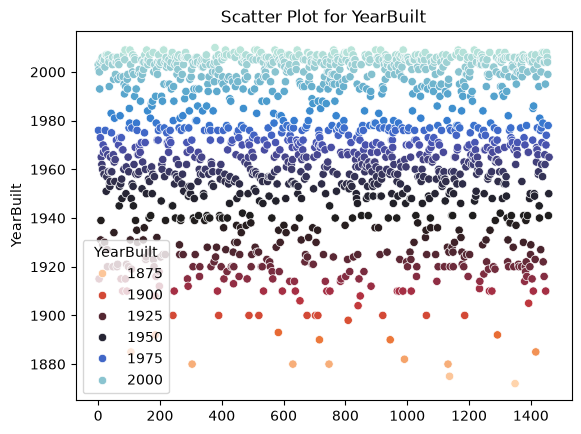

In [300]:
# Scatter plot
sns.scatterplot(x=range(len(column)), y=column, hue=column, palette='icefire_r')
plt.title("Scatter Plot for YearBuilt")
plt.show()

7. Recodificación

Al tratarse de una variable numérica, nos podría interesar partirla en intervalos, para ello vamos a ver la variable sin outliers.

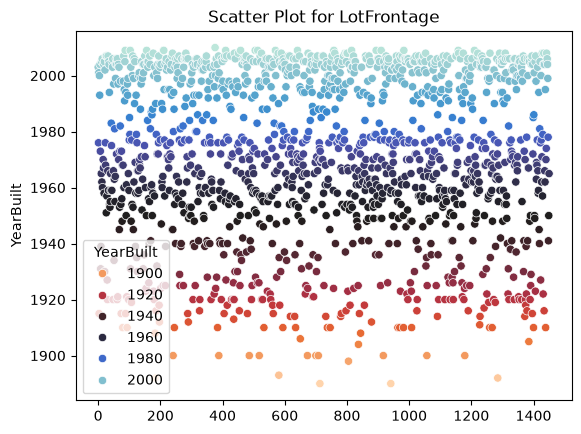

In [301]:
# Scatter plot
column2 = column[(column > (Q1 - 1.5 * RIC))]
column2 = column2[(column2 < (Q3 + 1.5 * RIC))]

sns.scatterplot(x=range(len(column2)), y=column2, hue=column2, palette='icefire_r')
plt.title("Scatter Plot for LotFrontage")
plt.show()

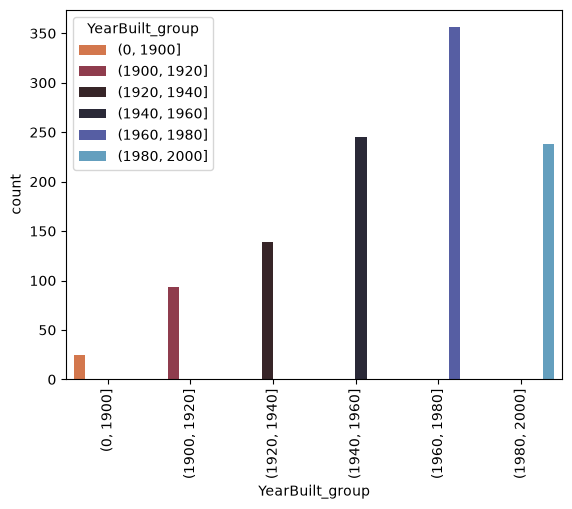

In [302]:
# Escogemos los rangos sugeridos por el hue
bins = [0, 1900, 1920, 1940, 1960, 1980, 2000]
df_test = pd.DataFrame({column.name: column, column.name+'_group': pd.cut(column, bins=bins, right=True)})

ax = sns.countplot(data=df_test, x=column.name+'_group', hue=column.name+'_group', palette='icefire_r')
ax.tick_params(axis='x', labelrotation=90)

---

##### - YearRemodAdd

In [303]:
column = df["YearRemodAdd"]
# 1. Valores únicos
print(column.unique())

[2003 1976 2002 1970 2000 1995 2005 1973 1950 1965 2006 1962 2007 1960
 2001 1967 2004 2008 1997 1959 1990 1955 1983 1980 1966 1963 1987 1964
 1972 1996 1998 1989 1953 1956 1968 1981 1992 2009 1982 1961 1993 1999
 1985 1979 1977 1969 1958 1991 1971 1952 1975 2010 1984 1986 1994 1988
 1954 1957 1951 1978 1974]


In [304]:
# 2. Tipos de Valores
print(column)

0       2003
1       1976
2       2002
3       1970
4       2000
        ... 
1455    2000
1456    1988
1457    2006
1458    1996
1459    1965
Name: YearRemodAdd, Length: 1460, dtype: int64


YearRemodAdd es una variable discreta, ya que lidia con valores númericos, pero estos representan el año de remodelación de la propiedad, por lo que se tratará de enteros específicamente, imposibilitando esto una vez más  que sea una variable continua.

In [305]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


In [306]:
# 5. Si la columna es numérica obtén valores mínimo y máximo; estudia si hay outliers
print("Máximo:")
print(column.max())
print("\nMínimo:")
print(column.min())

Q1 = column.quantile(0.25)
Q3 = column.quantile(0.75)
RIC = Q3 - Q1

print("\nOutliers:")
print(column[(column < (Q1 - 1.5 * RIC)) | (column > (Q3 + 1.5 * RIC))])

Máximo:
2010

Mínimo:
1950

Outliers:
Series([], Name: YearRemodAdd, dtype: int64)


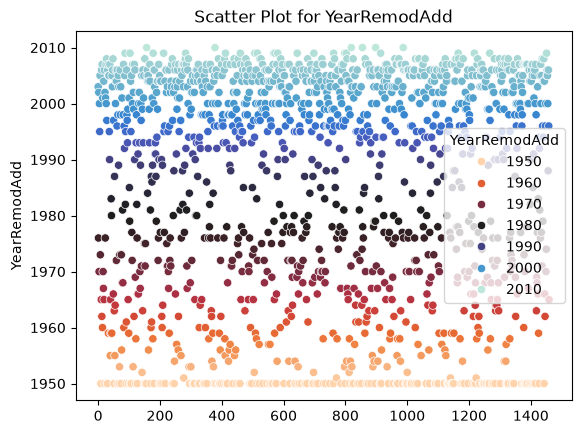

In [307]:
# Scatter plot
sns.scatterplot(x=range(len(column)), y=column, hue=column, palette='icefire_r')
plt.title("Scatter Plot for YearRemodAdd")
plt.show()

7. Recodificación

Al tratarse de una variable numérica, nos podría interesar partirla en intervalos, para ello vamos a ver la variable sin outliers.

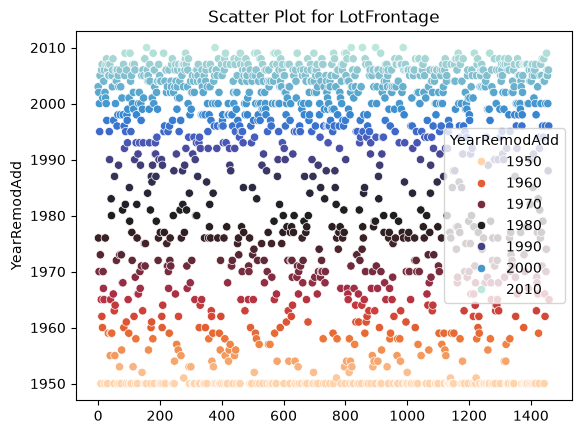

In [308]:
# Scatter plot
column2 = column[(column > (Q1 - 1.5 * RIC))]
column2 = column2[(column2 < (Q3 + 1.5 * RIC))]

sns.scatterplot(x=range(len(column2)), y=column2, hue=column2, palette='icefire_r')
plt.title("Scatter Plot for LotFrontage")
plt.show()

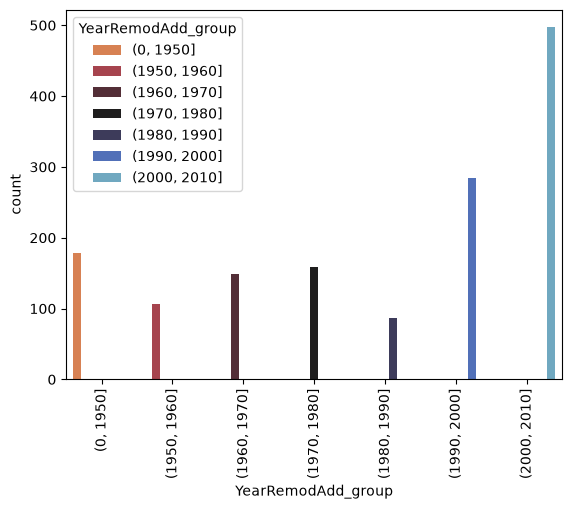

In [309]:
# Escogemos los rangos sugeridos por el hue
bins = [0, 1950, 1960, 1970, 1980, 1990, 2000, 2010]
df_test = pd.DataFrame({column.name: column, column.name+'_group': pd.cut(column, bins=bins, right=True)})

ax = sns.countplot(data=df_test, x=column.name+'_group', hue=column.name+'_group', palette='icefire_r')
ax.tick_params(axis='x', labelrotation=90)

---

##### - GarageCars, GarageArea, GarageQual, GarageCond, GarageType, GarageYrBlt, GarageFinish (se recomienda analizarlas en conjunto)

In [310]:
column1 = df["GarageCars"]
column2 = df["GarageArea"]
column3 = df["GarageQual"]
column4 = df["GarageCond"]
column5 = df["GarageType"]
column6 = df["GarageYrBlt"]
column7 = df["GarageFinish"]
# 1. Valores únicos
print(column1.unique())
print(column2.unique())
print(column3.unique())
print(column4.unique())
print(column5.unique())
print(column6.unique())
print(column7.unique())

[2 3 1 0 4]
[ 548  460  608  642  836  480  636  484  468  205  384  736  352  840
  576  516  294  853  280  534  572  270  890  772  319  240  250  271
  447  556  691  672  498  246    0  440  308  504  300  670  826  386
  388  528  894  565  641  288  645  852  558  220  667  360  427  490
  379  297  283  509  405  758  461  400  462  420  432  506  684  472
  366  476  410  740  648  273  546  325  792  450  180  430  594  390
  540  264  530  435  453  750  487  624  471  318  766  660  470  720
  577  380  434  866  495  564  312  625  680  678  726  532  216  303
  789  511  616  521  451 1166  252  497  682  666  786  795  856  473
  398  500  349  454  644  299  210  431  438  675  968  721  336  810
  494  457  818  463  604  389  538  520  309  429  673  884  868  492
  413  924 1053  439  671  338  573  732  505  575  626  898  529  685
  281  539  418  588  282  375  683  843  552  870  888  746  708  513
 1025  656  872  292  441  189  880  676  301  474  706  617  445

In [311]:
# 2. Tipo de las variables
print(column1)
print(column2)
print(column3)
print(column4)
print(column5)
print(column6)
print(column7)

0       2
1       2
2       2
3       3
4       3
       ..
1455    2
1456    2
1457    1
1458    1
1459    1
Name: GarageCars, Length: 1460, dtype: int64
0       548
1       460
2       608
3       642
4       836
       ... 
1455    460
1456    500
1457    252
1458    240
1459    276
Name: GarageArea, Length: 1460, dtype: int64
0       TA
1       TA
2       TA
3       TA
4       TA
        ..
1455    TA
1456    TA
1457    TA
1458    TA
1459    TA
Name: GarageQual, Length: 1460, dtype: str
0       TA
1       TA
2       TA
3       TA
4       TA
        ..
1455    TA
1456    TA
1457    TA
1458    TA
1459    TA
Name: GarageCond, Length: 1460, dtype: str
0       Attchd
1       Attchd
2       Attchd
3       Detchd
4       Attchd
         ...  
1455    Attchd
1456    Attchd
1457    Attchd
1458    Attchd
1459    Attchd
Name: GarageType, Length: 1460, dtype: str
0       2003.0
1       1976.0
2       2001.0
3       1998.0
4       2000.0
         ...  
1455    1999.0
1456    1978.0
1457    1941

GarageCars: Se trata de una variable discreta, ya que según data-description.txt representa el número de coches que caben
teóricamente en el garaje dado. De esta manera, corresponde a esta variable un valor natural (o 0 si no hay garaje), lo cual es incompatible
con un valor continuo.

GarageArea:Se trata de una variable continua, ya que según data-description.txt corresponde a una medida espacial en pies
 cuadrados del tamaño del garaje. De esta manera, siendo una medida espacial, es válido cualquier valor entre dos dados,
 400.643 y 400.644 por ejemplo, ya que representa un área real.

GarageQual: Se trata de una variable categórica con orden: corresponden a esta los valores Ex, Gd, TA, Fa y Po; que valoran un garaje
de excelente a pobre en una escala de calidad, ergo, hay un orden claro.

GarageCond: Al igual que con GarageQual se trata de una variable categórica con orden: corresponden a esta los valores Ex, Gd, TA, Fa y Po; que valoran el estado de un garaje
de excelente a pobre en una escala de estado, ergo, hay un orden claro.

GarageType: Se trata de una variable categórica sin orden, según data-description.txt hay 6 valores posibles,
y además NA significa en este caso que no hay garaje. Dado que no hay ninguna jerarquía asociada ni una escala inferible
de las categorías, no hay orden claro.

GarageYrBlt: Se trata de una variable discreta, ya que representa específicamente el año de construcción del garaje dado, tratándose
así de un valor númerico. Al ser específicamente años, se trata de números enteros y más específicamente naturales, imposibilitando que
la variable sea continua.

GarageFinish: Se trata de una variable categórica con orden, con 3 valores posibles: Fin, RFn y Unf; encontrándose estos en una
escala de que tan "finished" está el garaje. De esta manera, existe un orden claro.


In [312]:
# 3. Si hay valores nulos o no
column_na = column1.isnull().sum()
print(column_na[column_na>0])
column_na = column2.isnull().sum()
print(column_na[column_na>0])
column_na = column3.isnull().sum()
print(column_na[column_na>0])
column_na = column4.isnull().sum()
print(column_na[column_na>0])
column_na = column5.isnull().sum()
print(column_na[column_na>0])
column_na = column6.isnull().sum()
print(column_na[column_na>0])
column_na = column7.isnull().sum()
print(column_na[column_na>0])

[]
[]
[81]
[81]
[81]
[81]
[81]


In [313]:
# Lidiar con variables nulas
df = df.dropna(subset=["GarageType","GarageYrBlt","GarageFinish","GarageQual","GarageCond"])

Dado que los valores nulos son menores al 10%, se escoge la eliminación de casos para lidiar con los valores nulos. Para esto, hacemos uso de dropna, usando subset y asignándole el conjunto de columnas de garaje que estamos estudiando y sabemos que tienen valores nulos. Por defecto dropna se deshace de columnas asi que ningun otro parámetro tiene que ser añadido.

In [314]:
# 5. Si la columna es numérica obtén valores mínimo y máximo; estudia si hay outliers
print("GarageArea")
print("Máximo:")
print(column2.max())
print("\nMínimo:")
print(column2.min())

Q1 = column2.quantile(0.25)
Q3 = column2.quantile(0.75)
RIC = Q3 - Q1

print("\nOutliers:")
print(column2[(column2 < (Q1 - 1.5 * RIC)) | (column2 > (Q3 + 1.5 * RIC))])

print("\nGarageYrBlt")
print("Máximo:")
print(column6.max())
print("\nMínimo:")
print(column6.min())

Q1 = column6.quantile(0.25)
Q3 = column6.quantile(0.75)
RIC = Q3 - Q1

print("\nOutliers:")
print(column6[(column6 < (Q1 - 1.5 * RIC)) | (column6 > (Q3 + 1.5 * RIC))])

GarageArea
Máximo:
1418

Mínimo:
0

Outliers:
178     1166
224      968
270     1053
317     1025
408      947
581     1390
664     1134
718      983
803     1020
825     1220
1061    1248
1087    1043
1142    1052
1184     995
1190    1356
1228    1052
1241     954
1268    1014
1298    1418
1350     968
1417    1069
Name: GarageArea, dtype: int64

GarageYrBlt
Máximo:
2010.0

Mínimo:
1900.0

Outliers:
Series([], Name: GarageYrBlt, dtype: float64)


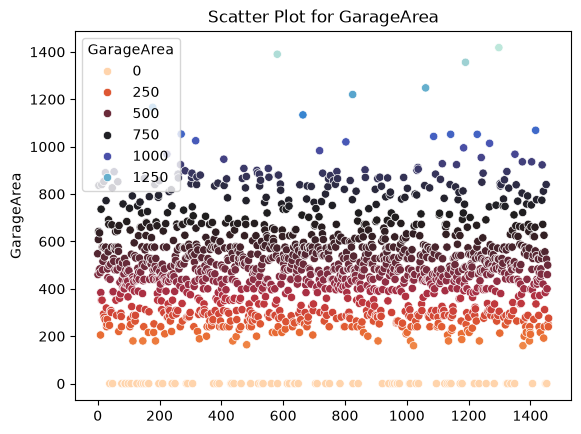

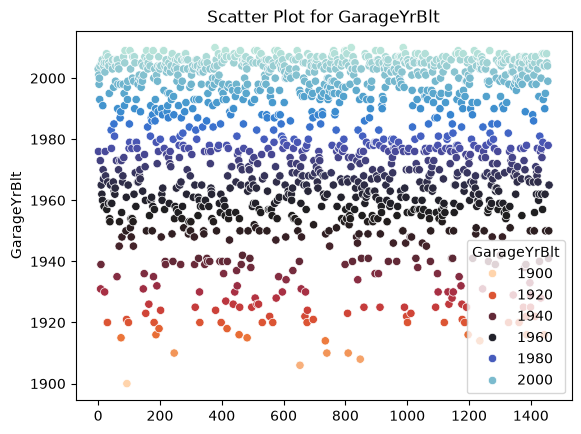

In [315]:
# Scatter plot
sns.scatterplot(x=range(len(column2)), y=column2, hue=column2, palette='icefire_r')
plt.title("Scatter Plot for GarageArea")
plt.show()

sns.scatterplot(x=range(len(column6)), y=column6, hue=column6, palette='icefire_r')
plt.title("Scatter Plot for GarageYrBlt")
plt.show()

---

##### - OverallQual

In [316]:
column = df["OverallQual"]
# 1. Valores únicos
print(column.unique())

[ 7  6  8  5  9  4 10  3  2]


In [317]:
# 2. Tipos de Valores
print(column)

0       7
1       6
2       7
3       7
4       8
       ..
1455    6
1456    6
1457    7
1458    5
1459    5
Name: OverallQual, Length: 1379, dtype: int64


Se trata de una variable categórica con orden, ya que según data-description.txt tiene 10 posibles valores (de Very Excellent a Very Poor) codificados con valores númericos, por lo que tienen un orden claro.

In [318]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


7. Recodificación

Se trata de una categórica ordenable a la que ya se le han sido asignado valores numéricos para sus categorías por lo que no es necesaria una recodificación.

---

##### - OverallCond

In [319]:
column = df["OverallCond"]
# 1. Valores únicos
print(column.unique())

[5 8 6 7 4 3 9 2]


In [320]:
# 2. Tipos de Valores
print(column)

0       5
1       8
2       5
3       5
4       5
       ..
1455    5
1456    6
1457    9
1458    6
1459    6
Name: OverallCond, Length: 1379, dtype: int64


Al igual que con OverallQual, se trata de una variable categórica con orden, ya que según data-description.txt tiene 10 posibles valores (de Very Excellent a Very Poor) codificados con valores númericos, por lo que tienen un orden claro.

In [321]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


7. Recodificación

Se trata de una categórica ordenable a la que ya se le han sido asignado valores numéricos para sus categorías por lo que no es necesaria una recodificación.

---

##### - SalePrice

In [322]:
column = df["SalePrice"]
# 1. Valores únicos
print(column.unique())

[208500 181500 223500 140000 250000 143000 307000 200000 129900 118000
 129500 345000 144000 279500 157000 132000 149000  90000 159000 139000
 325300 139400 230000 154000 256300 134800 306000 207500  68500  40000
 149350 179900 165500 277500 309000 145000 153000 109000 160000 170000
 130250 141000 319900 239686 249700 127000 177000 114500 110000 385000
 130000 180500 172500 196500 438780 124900 158000 101000 202500 219500
 317000 180000 226000  80000 225000 244000 185000 144900 107400  91000
 135750 193500 153500 245000 126500 168500 260000 174000 164500 109900
  98600 163500 133900 204750 214000  94750  83000 205000 178000 118964
 198900 169500 100000 115000 190000 136900 383970 217000 259500 176000
 155000 320000 163990 136000 153900 181000 128000 150000 150750 220000
 171000 231500 166000 204000 125000 105000 222500 122000 372402 235000
 109500 269500 254900 162500 412500 152000 325624 183500 228000 128500
 215000 239000 163000 184000 243000 211000 501837 200100 120000 475000
 17300

In [323]:
# 2. Tipos de Valores
print(column)

0       208500
1       181500
2       223500
3       140000
4       250000
         ...  
1455    175000
1456    210000
1457    266500
1458    142125
1459    147500
Name: SalePrice, Length: 1379, dtype: int64


Representa el precio de la propiedad, por lo que se trata necesariamente de una variable discreta, ya que entre dos valores distintos posibles necesariamente habrá de haber una distancia mínima númerica acorde a la unidad mínima de la moneda usada, imposibilitando la continuidad de esta variable.

In [324]:
# 3. Si hay valores nulos o no
column_na = column.isnull().sum()
print(column_na[column_na>0])

[]


In [325]:
# 5. Si la columna es numérica obtén valores mínimo y máximo; estudia si hay outliers
print("Máximo:")
print(column.max())
print("\nMínimo:")
print(column.min())

Q1 = column.quantile(0.25)
Q3 = column.quantile(0.75)
RIC = Q3 - Q1

print("\nOutliers:")
print(column[(column < (Q1 - 1.5 * RIC)) | (column > (Q3 + 1.5 * RIC))])

Máximo:
755000

Mínimo:
35311

Outliers:
11      345000
53      385000
58      438780
112     383970
151     372402
161     412500
178     501837
185     475000
224     386250
231     403000
278     415298
309     360000
313     375000
321     354000
336     377426
349     437154
378     394432
389     426000
440     555000
473     440000
477     380000
481     374000
496     430000
515     402861
527     446261
585     369900
591     451950
608     359100
642     345000
644     370878
654     350000
661     402000
664     423000
678     372500
688     392000
691     755000
702     361919
769     538000
774     395000
798     485000
803     582933
825     385000
877     350000
898     611657
987     395192
990     348000
1046    556581
1142    424870
1169    625000
1181    392500
1182    745000
1228    367294
1243    465000
1267    378500
1268    381000
1353    410000
1373    466500
1388    377500
1437    394617
Name: SalePrice, dtype: int64


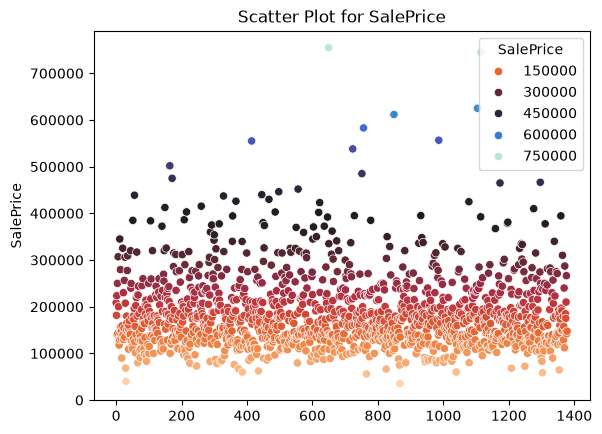

In [326]:
# Scatter plot
sns.scatterplot(x=range(len(column)), y=column, hue=column, palette='icefire_r')
plt.title("Scatter Plot for SalePrice")
plt.show()

7. Recodificación

Al tratarse de una variable numérica, nos podría interesar partirla en intervalos, para ello vamos a ver la variable sin outliers.

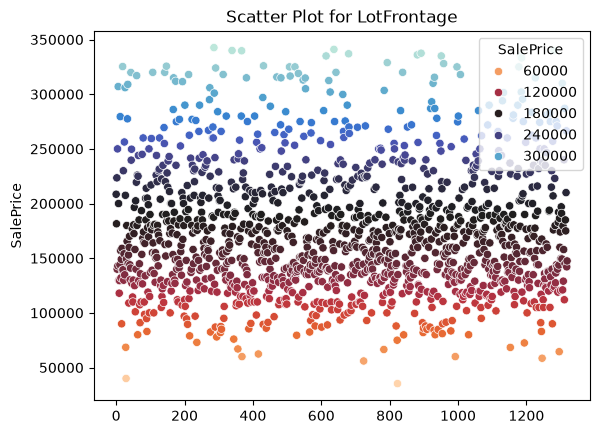

In [327]:
# Scatter plot
column2 = column[(column > (Q1 - 1.5 * RIC))]
column2 = column2[(column2 < (Q3 + 1.5 * RIC))]

sns.scatterplot(x=range(len(column2)), y=column2, hue=column2, palette='icefire_r')
plt.title("Scatter Plot for LotFrontage")
plt.show()

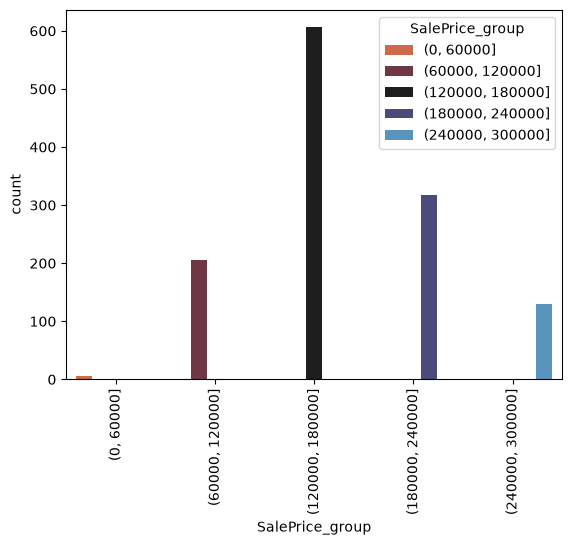

In [328]:
# Escogemos los rangos sugeridos por el hue
bins = [0, 60000, 120000, 180000, 240000, 300000]
df_test = pd.DataFrame({column.name: column, column.name+'_group': pd.cut(column, bins=bins, right=True)})

ax = sns.countplot(data=df_test, x=column.name+'_group', hue=column.name+'_group', palette='icefire_r')
ax.tick_params(axis='x', labelrotation=90)

---

### 6. Muestra un histograma de las variables LotFrontage, LotArea, SalePrice, OverallQual y comenta los resultados. Crea un gráfico de donut para variables categóricas como LandSlope y, Neighborhood. 
> Ayuda: un gráfico de donut es un gráfico de tarta quitando la parte central. 

A la vista de los resultados, ¿qué decisiones tomarías sobre estas tres variables?  
> Sugerencia: En los dos casos puede serte útil revisar el significado de estas columnas en el fichero data-description.txt 

##### Histograma

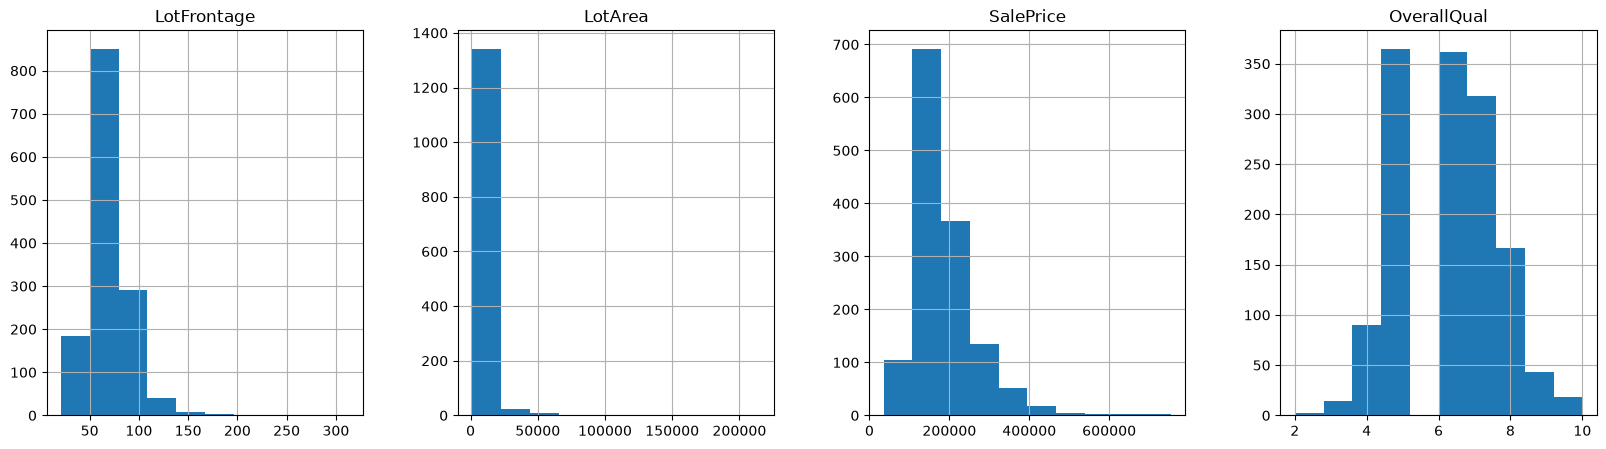

In [329]:
df.hist(column=['LotFrontage', 'LotArea', 'SalePrice', 'OverallQual'], layout=(1,4), figsize=(20,5));

cometarios


##### Gráficos de donut

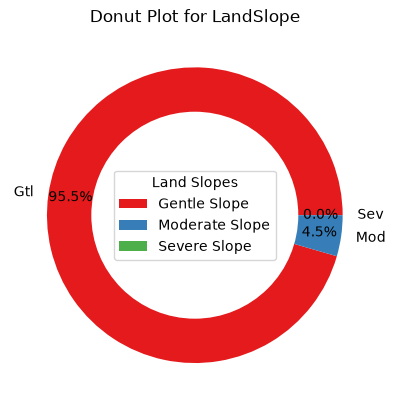

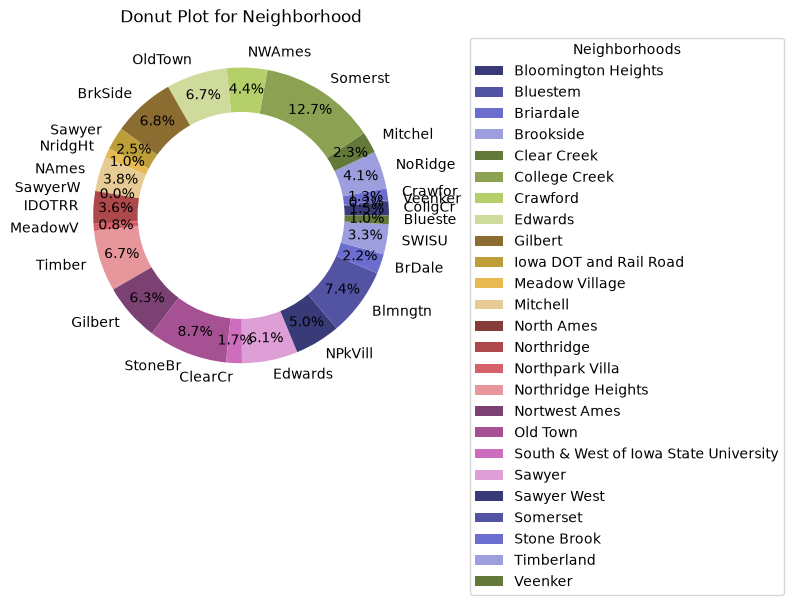

In [330]:
sizes = [df[df['LandSlope']=='Gtl'].count().sum(), df[df['LandSlope']=='Mod'].count().sum(), df[df['LandSlope']=='Sevv'].count().sum()]
labels = df['LandSlope'].unique()

plt.pie(sizes, colors=plt.cm.Set1.colors, labels=labels, autopct='%1.1f%%', pctdistance=0.85)

centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Donut Plot for LandSlope')
plt.legend(['Gentle Slope','Moderate Slope','Severe Slope'], loc="center", title="Land Slopes")

plt.show()

#--------------------------------------------------------------------------------------------------------------------------------------

sizes = [df[df['Neighborhood']=='Blmngtn'].count().sum(), df[df['Neighborhood']=='Blueste'].count().sum(), df[df['Neighborhood']=='BrDale'].count().sum(),
         df[df['Neighborhood']=='BrkSide'].count().sum(), df[df['Neighborhood']=='ClearCr'].count().sum(), df[df['Neighborhood']=='CollgCr'].count().sum(),
         df[df['Neighborhood']=='Crawfor'].count().sum(), df[df['Neighborhood']=='Edwards'].count().sum(), df[df['Neighborhood']=='Gilbert'].count().sum(),
         df[df['Neighborhood']=='IDOTRR'].count().sum(), df[df['Neighborhood']=='MeadowV'].count().sum(), df[df['Neighborhood']=='Mitchel'].count().sum(),
         df[df['Neighborhood']=='Names'].count().sum(), df[df['Neighborhood']=='NoRidge'].count().sum(), df[df['Neighborhood']=='NPkVill'].count().sum(),
         df[df['Neighborhood']=='NridgHt'].count().sum(), df[df['Neighborhood']=='NWAmes'].count().sum(), df[df['Neighborhood']=='OldTown'].count().sum(),
         df[df['Neighborhood']=='SWISU'].count().sum(), df[df['Neighborhood']=='Sawyer'].count().sum(), df[df['Neighborhood']=='SawyerW'].count().sum(),
         df[df['Neighborhood']=='Somerst'].count().sum(), df[df['Neighborhood']=='StoneBr'].count().sum(), df[df['Neighborhood']=='Timber'].count().sum(),
         df[df['Neighborhood']=='Veenker'].count().sum()]
labels = df['Neighborhood'].unique()

plt.pie(sizes, colors=plt.cm.tab20b.colors, labels=labels, autopct='%1.1f%%', pctdistance=0.85)

centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Donut Plot for Neighborhood')
plt.legend(['Bloomington Heights', 'Bluestem', 'Briardale', 'Brookside', 'Clear Creek', 'College Creek', 'Crawford', 'Edwards', 'Gilbert', 'Iowa DOT and Rail Road', 
            'Meadow Village', 'Mitchell', 'North Ames', 'Northridge', 'Northpark Villa', 'Northridge Heights', 'Nortwest Ames', 'Old Town', 
            'South & West of Iowa State University', 'Sawyer', 'Sawyer West', 'Somerset', 'Stone Brook', 'Timberland', 'Veenker'], bbox_to_anchor=(1.1,1), 
           loc="upper left", title="Neighborhoods")

plt.show()